# Part 1: Pre-processing, Language Models and Perplexity
In this part we build one bigram language model for positive reviews and one for negative reviews,
then use them as a classifier (the model that finds the review less surprising wins).

In [12]:
import random
from datasets import load_dataset
import math

# loading dataset and splitting

In [13]:
random.seed(42) # define a seed that will work on
raw = load_dataset("stanfordnlp/imdb") #Load data
train_pos = []
train_neg = []
test_pos = []
test_neg = []

for row in raw["train"]:    #extractsamples  train class
    if row["label"] == 1:
        train_pos.append(row["text"])
    else:
        train_neg.append(row["text"])

random.shuffle(train_pos)
random.shuffle(train_neg)
train_pos = train_pos[:2500] #Pick train samples after shuffling
train_neg = train_neg[:2500]

 #do the same procedure for the test
for row in raw["test"]:
    if row["label"] == 1:
        test_pos.append(row["text"])
    else:
        test_neg.append(row["text"])
random.shuffle(test_pos)
random.shuffle(test_neg)

test_pos = test_pos[:500]
test_neg = test_neg[:500] #pick 1000 test/ 500 pos/500 neg


print("train pos:", len(train_pos))
print("train neg:", len(train_neg))
print("test pos:", len(test_pos))
print("test neg:", len(test_neg))

train pos: 2500
train neg: 2500
test pos: 500
test neg: 500


In [14]:
print(train_pos[0][:600])
print("-----")
print(train_neg[0][:600])
print("-----")
print(train_neg[1][:600])

A friend lent me this DVD, which he got from the director at a festival, I think. I went in warned that some of the technical aspects of the movie were a bit shaky and that the writing was good but not great. So maybe that colored my judgment but I have to admit that I liked this movie.<br /><br />The standouts where the actors. Youssef Kerkor was really good as Ernie, the main character, kind of pathetic in a likable way. Adam Jones (who also directed) and Justin Lane were excellent as the roommates who drive Ernie mad. The Bill character (Justin Lane), who spends a lot of the film dressed li
-----
You MUST be kidding!!!! Let's entertain the possibility that Parker Posey is really an actress, and not just some entry in the "quirk of the month club" of actors. Really, unless this is meant to be a tongue-in-cheek satire on David Mamet-- terse, confusing dialog delivered alternately in machine gun rapidity or monotone (think Ben Stein) blandness--or a flat out dry comedy; this film has g

## what we noticed in the raw reviews
- the text has `<br /><br />` html tags in it (if we leave them, "br" becomes a fake word)
- there is mixed capitalisation ("Great" vs "great") and a lot of punctuation
- `!` and `?` carry emotion ("!!!!"), so we keep them as their own tokens
- everything else (dots, quotes, dashes...) is just noise for counting, so we turn it into a space

In [15]:
def normalize_review(review):
    # characters we keep exactly as they are
    KEEP_CHARS = "abcdefghijklmnopqrstuvwxyz0123456789'"
    # emotion symbols we keep, but as separate tokens
    EMOTION_MARKS = "!?"
    #  remove the HTML line-break tag first, so "br" never becomes a fake word
    review = review.replace("<br />", " ")
    #  lowercase so "Great" and "great" share one count
    review = review.lower()
    #  rebuild the text one character at a time
    cleaned = ""
    for char in review:
        if char in KEEP_CHARS:
            cleaned = cleaned + char
        elif char in EMOTION_MARKS:   # i need my emotion marks to show like questioning or excitement
            cleaned = cleaned + " " + char + " "
        else:  #no need to puncutation to  take them as counts
            cleaned = cleaned + " "

    return cleaned

## tokenizing
we cut the cleaned text into words and pad each review with `<s>` (start) and `</s>` (end),
so the model knows how a review starts and how it ends.

In [16]:
def tokenize_review(review):
    cleaned = normalize_review(review)    # clean the text first
    words = cleaned.split()               # cut into a list of words
    tokens = ["<s>"] + words + ["</s>"]   # add start and end markers
    return tokens

# quick check on a small made-up review
print(tokenize_review("Great movie!<br />Don't miss it."))

['<s>', 'great', 'movie', '!', "don't", 'miss', 'it', '</s>']


In [17]:
train_pos_tokens = []
for review in train_pos:
    train_pos_tokens.append(tokenize_review(review))

train_neg_tokens = []
for review in train_neg:
    train_neg_tokens.append(tokenize_review(review))

test_pos_tokens = []
for review in test_pos:
    test_pos_tokens.append(tokenize_review(review))

test_neg_tokens = []
for review in test_neg:
    test_neg_tokens.append(tokenize_review(review))

print("train pos:", len(train_pos_tokens))
print("train neg:", len(train_neg_tokens))
print("test pos:", len(test_pos_tokens))
print("test neg:", len(test_neg_tokens))

print()
print("first 15 tokens of the first positive review:")
print(train_pos_tokens[0][:15])
print("last 5 tokens:")
print(train_pos_tokens[0][-5:])

train pos: 2500
train neg: 2500
test pos: 500
test neg: 500

first 15 tokens of the first positive review:
['<s>', 'a', 'friend', 'lent', 'me', 'this', 'dvd', 'which', 'he', 'got', 'from', 'the', 'director', 'at', 'a']
last 5 tokens:
['adam', 'jones', 'and', 'crew', '</s>']


## counting the bigrams
for every review we slide over the tokens two at a time.
- `bigram_counts[(a, b)]` = how many times word `b` came right after word `a`
- `context_counts[a]` = how many times `a` appeared as the first word of a pair (we divide by this later)

we do it once for the positive reviews and once for the negative reviews.

In [18]:
def count_bigrams(token_lists):
    bigram_counts = {}
    context_counts = {}

    for tokens in token_lists:
        for i in range(len(tokens) - 1):      # stop one early because we look at i and i+1
            prev_word = tokens[i]
            word = tokens[i + 1]
            pair = (prev_word, word)
            bigram_counts[pair] = bigram_counts.get(pair, 0) + 1            # count this pair
            context_counts[prev_word] = context_counts.get(prev_word, 0) + 1  # count the first word

    return bigram_counts, context_counts


pos_bigrams, pos_contexts = count_bigrams(train_pos_tokens)
neg_bigrams, neg_contexts = count_bigrams(train_neg_tokens)

print("positive: different bigrams =", len(pos_bigrams))
print("negative: different bigrams =", len(neg_bigrams))

# sanity check: some phrases should lean towards one class
print()
print("how often does 'not good' appear?")
print("  in positive reviews:", pos_bigrams.get(("not", "good"), 0))
print("  in negative reviews:", neg_bigrams.get(("not", "good"), 0))
print("how often does 'a must' appear?")
print("  in positive reviews:", pos_bigrams.get(("a", "must"), 0))
print("  in negative reviews:", neg_bigrams.get(("a", "must"), 0))

positive: different bigrams = 254924
negative: different bigrams = 244247

how often does 'not good' appear?
  in positive reviews: 6
  in negative reviews: 20
how often does 'a must' appear?
  in positive reviews: 77
  in negative reviews: 5


## vocabulary size
Laplace (add-1) smoothing needs `V`, the number of different words. we take it from the training data of both classes.

In [19]:
vocab = set()

for tokens in train_pos_tokens:
    for word in tokens:
        vocab.add(word) # see all vocab in train pos

for tokens in train_neg_tokens:
    for word in tokens:
        vocab.add(word) #see all vocab in train neg

V = len(vocab)
print("vocabulary size V:", V)

vocabulary size V: 42587


## bigram probability with add-1 smoothing
$$P(word \mid prev) = \frac{count(prev, word) + 1}{count(prev) + V}$$
the +1 and +V make sure a bigram we never saw still gets a small probability instead of 0
(a single 0 would make the whole review's probability 0).

In [20]:
def bigram_prob(prev_word, word, bigrams, contexts, V):
    pair_count = bigrams.get((prev_word, word), 0)    # 0 if we never saw this pair
    context_count = contexts.get(prev_word, 0)        # 0 if we never saw this first word
    return (pair_count + 1) / (context_count + V)

## log-likelihood and perplexity
- **log-likelihood** = sum of `log P(word | prev)` over the review (we add logs instead of multiplying tiny numbers)
- **perplexity** = `exp(-log-likelihood / N)` where N is the number of bigrams. lower = the model is less surprised by the review

In [21]:
def log_likelihood(tokens, bigrams, contexts, V):
    total = 0.0
    for i in range(len(tokens) - 1):
        p = bigram_prob(tokens[i], tokens[i + 1], bigrams, contexts, V)
        total = total + math.log(p)      # add the log of each bigram probability
    return total


def perplexity(tokens, bigrams, contexts, V):
    ll = log_likelihood(tokens, bigrams, contexts, V)
    n = len(tokens) - 1                  # number of bigrams in the review
    return math.exp(-ll / n)

### scoring a brand new document
the assignment wants a function that takes a new document (raw text). this one tokenizes it first,
then returns the log-likelihood and perplexity under **both** models.

In [22]:
def score_document(text):
    tokens = tokenize_review(text)

    ll_pos = log_likelihood(tokens, pos_bigrams, pos_contexts, V)
    ll_neg = log_likelihood(tokens, neg_bigrams, neg_contexts, V)
    pp_pos = perplexity(tokens, pos_bigrams, pos_contexts, V)
    pp_neg = perplexity(tokens, neg_bigrams, neg_contexts, V)

    return ll_pos, ll_neg, pp_pos, pp_neg


new_review = "This movie was a great watch, the acting was wonderful!"
ll_pos, ll_neg, pp_pos, pp_neg = score_document(new_review)

print("review:", new_review)
print("log-likelihood  POS:", ll_pos, " NEG:", ll_neg)
print("perplexity      POS:", pp_pos, " NEG:", pp_neg)

review: This movie was a great watch, the acting was wonderful!
log-likelihood  POS: -76.15606870235682  NEG: -78.07757383882061
perplexity      POS: 570.4006784510754  NEG: 669.4553601904522


## using the language models as a classifier
for each test review we compute the perplexity under both models and pick the class with the **lower** perplexity.
(label 1 = positive, 0 = negative)

In [23]:
def predict_by_perplexity(tokens):
    pp_pos = perplexity(tokens, pos_bigrams, pos_contexts, V)
    pp_neg = perplexity(tokens, neg_bigrams, neg_contexts, V)

    if pp_pos < pp_neg:
        return 1      # positive model is less surprised
    else:
        return 0      # negative model is less surprised

In [24]:
test_tokens = test_pos_tokens + test_neg_tokens
true_labels = [1] * len(test_pos_tokens) + [0] * len(test_neg_tokens)

predictions = []
for tokens in test_tokens:
    predictions.append(predict_by_perplexity(tokens))

print("reviews:", len(test_tokens))
print("first 5 predictions:", predictions[:5])
print("first 5 true labels:", true_labels[:5])

reviews: 1000
first 5 predictions: [1, 1, 1, 0, 1]
first 5 true labels: [1, 1, 1, 1, 1]


### accuracy, precision, recall, F1
we count the four outcomes (TP, TN, FP, FN) by hand and build the metrics from them.

In [25]:
def evaluate(true_labels, predictions):
    TP = 0   # said positive, was positive
    TN = 0   # said negative, was negative
    FP = 0   # said positive, was negative
    FN = 0   # said negative, was positive

    for i in range(len(true_labels)):
        actual = true_labels[i]
        guess = predictions[i]

        if actual == 1 and guess == 1:
            TP = TP + 1
        elif actual == 0 and guess == 0:
            TN = TN + 1
        elif actual == 0 and guess == 1:
            FP = FP + 1
        else:
            FN = FN + 1

    accuracy = (TP + TN) / len(true_labels)

    # the if checks only avoid dividing by zero
    if TP + FP > 0:
        precision = TP / (TP + FP)
    else:
        precision = 0.0

    if TP + FN > 0:
        recall = TP / (TP + FN)
    else:
        recall = 0.0

    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0

    return accuracy, precision, recall, f1

In [26]:
acc, prec, rec, f1 = evaluate(true_labels, predictions)

print("Bigram LM classifier on 1000 test reviews")
print("accuracy :", round(acc, 4))
print("precision:", round(prec, 4))
print("recall   :", round(rec, 4))
print("F1       :", round(f1, 4))

Bigram LM classifier on 1000 test reviews
accuracy : 0.876
precision: 0.8966
recall   : 0.85
F1       : 0.8727


## LM inference: next word prediction
`predict_next_word` looks at every word in the vocabulary and returns the one with the highest probability after the previous word.
`generate_text` calls it again and again, adding the predicted word each time, until it predicts `</s>` or reaches the max length.

In [27]:
vocab_list = sorted(vocab)     # turn the set into a list we can loop over

def predict_next_word(prev_word, bigrams, contexts, V):
    best_word = None
    best_prob = 0.0

    for w in vocab_list:
        if w == "<s>":          # <s> can never come in the middle of a review
            continue
        p = bigram_prob(prev_word, w, bigrams, contexts, V)
        if p > best_prob:       # keep the most probable word so far
            best_prob = p
            best_word = w

    return best_word, best_prob

In [28]:
print("after '<s>'  (POS):", predict_next_word("<s>", pos_bigrams, pos_contexts, V))
print("after '<s>'  (NEG):", predict_next_word("<s>", neg_bigrams, neg_contexts, V))
print("after 'not'  (POS):", predict_next_word("not", pos_bigrams, pos_contexts, V))
print("after 'not'  (NEG):", predict_next_word("not", neg_bigrams, neg_contexts, V))


after '<s>'  (POS): ('i', 0.00969237252423093)
after '<s>'  (NEG): ('i', 0.0104021114733737)
after 'not'  (POS): ('a', 0.004204455401954741)
after 'not'  (NEG): ('a', 0.004259222855645109)


In [29]:
def generate_text(sentence, bigrams, contexts, V, max_length=20):
    words = normalize_review(sentence).split()   # clean the starting sentence the same way as the training data
    tokens = ["<s>"] + words

    generated_count = 0
    while generated_count < max_length:
        next_word, prob = predict_next_word(tokens[-1], bigrams, contexts, V)

        if next_word == "</s>":      # the model decided the review is over
            break

        tokens.append(next_word)
        generated_count = generated_count + 1

    return " ".join(tokens[1:])      # drop <s> when showing the text

In [30]:
starts = ["this movie was", "i really", "the acting is"]

for s in starts:
    print("start        :", s)
    print("POS model    :", generate_text(s, pos_bigrams, pos_contexts, V))
    print("NEG model    :", generate_text(s, neg_bigrams, neg_contexts, V))
    print()

start        : this movie was
POS model    : this movie was a great movie is a great movie is a great movie is a great movie is a great movie is
NEG model    : this movie was a movie is a movie is a movie is a movie is a movie is a movie is a movie

start        : i really
POS model    : i really good as a great movie is a great movie is a great movie is a great movie is a great
NEG model    : i really bad acting is a movie is a movie is a movie is a movie is a movie is a movie

start        : the acting is
POS model    : the acting is a great movie is a great movie is a great movie is a great movie is a great movie is
NEG model    : the acting is a movie is a movie is a movie is a movie is a movie is a movie is a movie



## Part 1 summary
- the bigram LM classifier got **0.876 accuracy** and **0.8727 F1** on the 1000 test reviews
- the generated text starts sensibly ("a great movie", "bad acting") but then loops ("a great movie is a great movie ...").
  this happens because we always pick the single most probable next word (greedy), and a bigram only remembers one word,
  so once it reaches a word like "movie" it keeps falling back into the same cycle. the positive model still prefers "great" and the negative one "bad", which shows the two models learned different sentiment.

# Part 2: Vocabulary, Naive Bayes, and Log-Ratios


## Getting Most Frequent 2000 Features


In [31]:
combined = {}
for d in (pos_bigrams, neg_bigrams, pos_contexts, neg_contexts):
    for pair, count in d.items():
        combined[pair] = combined.get(pair, 0) + count # Merge all 4 dictionaries together

top_2000 = sorted(combined.items(), key=lambda item: item[1], reverse=True)[:2000] # sort them by count and pick the top 2000
vocab_count = dict(top_2000) # put them in a  sperate dictionary
vocab = {feature: i for i, feature in enumerate(vocab_count)} # create a dictionary with the feature as key and index as value
print("Positive bigrams:", list(pos_bigrams.items())[:5])
print("Negative bigrams:", list(neg_bigrams.items())[:5])
print("Vocabulary (top 5):", list(vocab.items())[:5])

Positive bigrams: [(('<s>', 'a'), 92), (('a', 'friend'), 22), (('friend', 'lent'), 1), (('lent', 'me'), 1), (('me', 'this'), 15)]
Negative bigrams: [(('<s>', 'you'), 22), (('you', 'must'), 8), (('must', 'be'), 53), (('be', 'kidding'), 3), (('kidding', '!'), 3)]
Vocabulary (top 5): [('the', 0), ('and', 1), ('a', 2), ('of', 3), ('to', 4)]


In [32]:
#testing to see if pairs exist
if ("the", "movie") in vocab:
    print("found it")
else:
    print("not in vocab")

found it


## Features count in their classes


In [33]:
pos_vocab = {}
for source in (pos_contexts, pos_bigrams): # getting count of each feature in the vocab for positive class
    for feature, count in source.items():
        if feature in vocab:
            pos_vocab[feature] = count

neg_vocab = {}
for source in (neg_contexts, neg_bigrams): # getting count of each feature in the vocab for negative class
    for feature, count in source.items():
        if feature in vocab:
            neg_vocab[feature] = count

len(pos_vocab), len(neg_vocab)
list(pos_vocab.items())[:5]

[('<s>', 2500), ('a', 16726), ('friend', 146), ('me', 1081), ('this', 6960)]

## Features Probabilities + Smoothing


In [34]:
total_pos = sum(pos_contexts.values())
total_neg = sum(neg_contexts.values())

def smoothed_probs(vocab, class_vocab):
    total = sum(class_vocab.get(feature, 0) for feature in vocab)   # all vocab counts in this class
    V = len(vocab)   # 2000

    probs = {}
    for feature in vocab:
        count = class_vocab.get(feature, 0)              # 0 if never seen in this class
        probs[feature] = (count + 1) / (total + V)     #compute the smoothed probability of each feature

    return probs


prob_pos = smoothed_probs(vocab, pos_vocab)
prob_neg = smoothed_probs(vocab, neg_vocab)


## Calculating the Log Ratios


In [35]:
def log_ratio(prob_pos, prob_neg):
    log_ratios = {}
    for feature in prob_pos:
        log_ratios[feature] = math.log(prob_pos[feature]) - math.log(prob_neg[feature])
    return log_ratios

log_ratios = log_ratio(prob_pos, prob_neg)
list(log_ratios.items())[:5]

[('the', 0.04546941267604643),
 ('and', 0.19806660583725488),
 ('a', 0.07510238732980756),
 ('of', 0.14019990408400762),
 ('to', -0.04353639415731081)]

## Class Predictions Using the Log Ratios


In [ ]:
prior_log_ratio = math.log(len(train_pos_tokens) / len(train_neg_tokens))

def predict_class(review, log_ratios):
    tokens = tokenize_review(review) # tokenize the review
    score = prior_log_ratio
    for i in range(len(tokens) - 1):
        prev_word = tokens[i]
        word = tokens[i + 1]
        pair = (prev_word, word)
        if pair in log_ratios: # check if the bigram exists in the log_ratios dictionary
            score += log_ratios[pair]
        if word in log_ratios: # check if the unigram exists in the log_ratios dictionary
            score += log_ratios[word]
    return "pos" if score > 0 else "neg" # return "pos" if score > 0 else "neg"



## Evaluation


In [46]:
def evaluate(test_pos, test_neg, log_ratios):
    correct = 0
    total = 0
    TP=0
    FP=0
    TN=0
    FN=0

    for review in test_pos:
        prediction = predict_class(review, log_ratios)
        if prediction == "pos":
            correct += 1
            TP += 1
        else:
            FN += 1
        total += 1

    for review in test_neg:
        prediction = predict_class(review, log_ratios)
        if prediction == "neg":
            correct += 1
            TN += 1
        else:
            FP += 1
        total += 1

    accuracy = correct / total
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    F1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    print(f"Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {F1_score:.4f}")
    return accuracy, precision, recall, F1_score



acc_nb, prec_nb, rec_nb, f1_nb = evaluate(test_pos, test_neg, log_ratios)



<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>
<s>


# part 3: NB-Weighted Logistic Regression

In [38]:
import random
import re
from collections import Counter

import numpy as np
from datasets import load_dataset


import matplotlib.pyplot as plt

In [39]:
# 1. Feature Matrix Construction
# Build a feature matrix X of shape (num_documents, 2000).
# Multiply the count of the feature in the document by its Log-Ratio rj to provide the model
# with dense sentiment signals:
# Xi,j = count(featurej in doci) × rj

# 2. Standardization: Standardize your feature matrix (Z-score normalization) and add a Bias column of 1s.

def build_feature_matrix(reviews, feature_list, log_ratios,
                         mean=None, sigma=None):

    idx = {feature: j for j, feature in enumerate(feature_list)}
    X = np.zeros((len(reviews), len(feature_list)), dtype=float)

    for i, review in enumerate(reviews):
        tokens = tokenize_review(review)

        # Count unigrams and bigrams using the same tokens as Part 1
        feature_counts = Counter(tokens)

        for j in range(len(tokens) - 1):
            feature_counts[(tokens[j], tokens[j + 1])] += 1

        # Fill the document's feature vector
        for feature, count in feature_counts.items():
            column = idx.get(feature)
            if column is not None:
                X[i, column] = count

    # Weight each feature by its log-count ratio from Part 2
    X *= np.asarray(log_ratios)

    # Fit standardization statistics on training data only
    if mean is None:
        mean = X.mean(axis=0)
        sigma = X.std(axis=0)
        sigma[sigma == 0] = 1.0

    X = (X - mean) / sigma

    # Add the bias column
    X = np.column_stack((np.ones(len(X)), X))

    return X, mean, sigma


In [40]:
# 3. Gradient Descent:
# Implement a Logistic Regression class from scratch.
# Write a training loop using Gradient Descent to minimize Binary Cross-Entropy Loss. Train this model on your standardized X matrix.

class LogisticRegression:

    def __init__(self, lr=0.1, n_iters=1000, l2=0.0, tol=1e-7, verbose=True):
        self.lr = lr              # learning rate (step size)
        self.n_iters = n_iters    # max number of gradient steps
        self.l2 = l2              # L2 strength (0 = no regularization)
        self.tol = tol            # stop if loss improves by less than this
        self.verbose = verbose
        self.w = None
        self.loss_history = []

    # helpers
    @staticmethod
    def _sigmoid(z):
        # numerically stable: never calls exp on a large positive number
        out = np.empty_like(z, dtype=float)
        # compute sigmoid in two cases: z >= 0 and z < 0
        pos = z >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
        out[~pos] = np.exp(z[~pos]) / (1.0 + np.exp(z[~pos]))
        return out

    # loss = binary cross-entropy + L2 regularization
    def _loss(self, y, p):
        eps = 1e-12                       # avoid log(0)
        # clip predictions to prevent log(0)
        p = np.clip(p, eps, 1 - eps)
        # compute binary cross-entropy loss + L2 regularization
        bce = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        reg = 0.5 * self.l2 * np.sum(self.w[1:] ** 2)   # skip bias
        return bce + reg

    # training
    def fit(self, X, y):
        n, d = X.shape
        y = np.asarray(y, dtype=float)
        self.w = np.zeros(d)
        self.loss_history = []

        for it in range(self.n_iters):
            p = self._sigmoid(X @ self.w)            # forward pass
            grad = X.T @ (p - y) / n                 # dLoss/dw for BCE
            grad[1:] += self.l2 * self.w[1:]         # L2 term (not on bias)
            self.w -= self.lr * grad                 # gradient descent step

            loss = self._loss(y, self._sigmoid(X @ self.w))
            self.loss_history.append(loss)

            if self.verbose and (it % 100 == 0 or it == self.n_iters - 1):
                acc = np.mean(self.predict(X) == y)
                print(f"iter {it:5d} | loss {loss:.5f} | train acc {acc:.4f}")

            if it > 0 and abs(self.loss_history[-2] - loss) < self.tol:
                if self.verbose:
                    print(f"converged at iter {it}")
                break
        return self

    # inference
    def predict_proba(self, X):
        return self._sigmoid(X @ self.w)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

Number of features: 2000
Most negative features: [('pointless', np.float64(-2.8208)), ('awful', np.float64(-2.6032)), (('waste', 'of'), np.float64(-2.5832)), ('waste', np.float64(-2.4824)), (('the', 'worst'), np.float64(-2.4091)), ('worst', np.float64(-2.3001)), (('so', 'bad'), np.float64(-2.1001)), ('wasted', np.float64(-1.9434)), (('your', 'time'), np.float64(-1.9099)), ('badly', np.float64(-1.8358))]
Most positive features: [(('a', 'wonderful'), np.float64(1.7073)), ('wonderful', np.float64(1.5793)), ('superb', np.float64(1.5682)), ('powerful', np.float64(1.5584)), ('fantastic', np.float64(1.4858)), ('excellent', np.float64(1.3503)), ('amazing', np.float64(1.3018)), ('brilliant', np.float64(1.2716)), (('my', 'favorite'), np.float64(1.2468)), ('recommended', np.float64(1.2433))]
X_train: (5000, 2001)
X_test: (1000, 2001)
iter     0 | loss 0.61021 | train acc 0.8312
iter    99 | loss 0.32108 | train acc 0.9326

Train accuracy: 0.9326
Test accuracy: 0.854


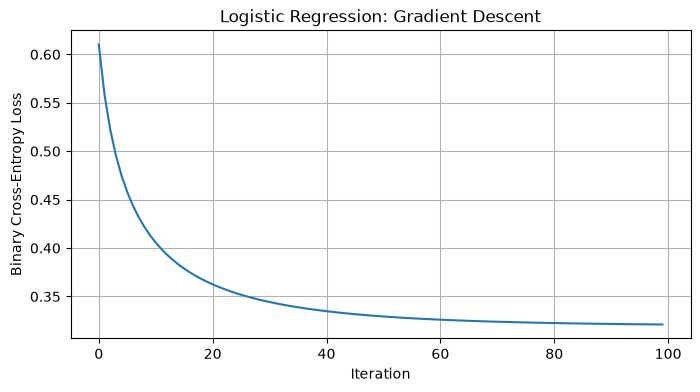

In [41]:

# Part 3: Logistic Regression using Log-Count Ratios

SEED = 42
np.random.seed(SEED)

# 1. Use the same top-2000 features selected in Part 2
features = list(vocab.keys())

# Get each feature's log ratio from Part 2
feature_log_ratios = np.array([
    log_ratios[feature] for feature in features
])

print("Number of features:", len(features))

# Show the most negative and positive log-ratio features
order = np.argsort(feature_log_ratios)

print("Most negative features:",
      [(features[j], round(feature_log_ratios[j], 4))
       for j in order[:10]])

print("Most positive features:",
      [(features[j], round(feature_log_ratios[j], 4))
       for j in order[::-1][:10]])

# 2. Build the training and test matrices
# Use the same train/test reviews from Part 1
train_reviews = train_pos + train_neg
test_reviews = test_pos + test_neg

y_train = np.array(
    [1] * len(train_pos) + [0] * len(train_neg)
)

y_test = np.array(
    [1] * len(test_pos) + [0] * len(test_neg)
)

X_train, mu, sigma = build_feature_matrix(
    train_reviews, features, feature_log_ratios
)

# Use training mean and standard deviation for test data
X_test, _, _ = build_feature_matrix(
    test_reviews, features, feature_log_ratios, mu, sigma
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# 3. Shuffle training rows
perm = np.random.RandomState(SEED).permutation(len(y_train))
X_train = X_train[perm]
y_train = y_train[perm]

# 4. Train Logistic Regression using Gradient Descent
model = LogisticRegression(
    lr=0.1,
    n_iters=100,
    l2=0.1,
    verbose=True
)

model.fit(X_train, y_train)

# 5. Evaluate the model
print("\nTrain accuracy:", round(model.score(X_train, y_train), 4))
print("Test accuracy:", round(model.score(X_test, y_test), 4))

# 6. Plot the loss curve
plt.figure(figsize=(8, 4))
plt.plot(model.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression: Gradient Descent")
plt.grid(True)
plt.show()


## Evaluation

In [42]:
def evaluate_lr(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return accuracy, precision, recall, f1_score

# 7. Evaluate Logistic Regression on the test set
y_pred = model.predict(X_test)
lr_acc, lr_prec, lr_rec, lr_f1 = evaluate_lr(y_test, y_pred)

print("\nLogistic Regression on test reviews")
print(f"Accuracy : {lr_acc:.4f}")
print(f"Precision: {lr_prec:.4f}")
print(f"Recall   : {lr_rec:.4f}")
print(f"F1 Score : {lr_f1:.4f}")



Logistic Regression on test reviews
Accuracy : 0.8540
Precision: 0.8512
Recall   : 0.8580
F1 Score : 0.8546


In [43]:
print(f"Accuracy: {acc} {acc_nb} {lr_acc}")
print(f"F1 Score: {f1} {f1_nb} {lr_f1}")

Accuracy: 0.876 0.807 0.854
F1 Score: 0.8726899383983572 0.8024564994882293 0.8545816733067729


## Part 4: Model Comparison and Discussion

| Model | Input Representation | Accuracy | F1 Score |
|---|---|---|---|
| Bigram Language Model | Word sequences: one bigram LM per class over the full vocabulary (about 42k words, about 250k distinct bigrams), classified by lower perplexity | 0.8760 | 0.8727 |
| Naive Bayes (Log-Ratio) | Bag of the 2,000 most frequent unigrams and bigrams; summed log-count ratios plus the class prior | 0.8070 | 0.8025 |
| Logistic Regression | The same 2,000 features, with counts multiplied by r_j and z-score standardized, plus a bias column; weights learned by gradient descent | 0.8540 | 0.8546 |

### Which model performed best?
The **Bigram Language Model** performed best (accuracy 0.8760, F1 0.8727). Logistic Regression came in second with a solid improvement (0.8540 / 0.8546) compared to Naive Bayes, which was last (0.8070 / 0.8025). The gap between the LM and Naive Bayes is about 7 percentage points, while Logistic Regression bridges more than half of that gap, trailing the LM by only about 2.2 percentage points.

### Possible explanations

**Why the LM wins.** The LM scores reviews using all bigrams present in the training data (over 240k unique bigrams per class), allowing it to utilize a vast, rich long-tail vocabulary. Naive Bayes and Logistic Regression are restricted to the top 2,000 features, which are heavily dominated by high-frequency function words and generic phrases ("of the", "and", "this movie") containing very little sentiment. Many highly specific sentiment-bearing words and phrases are simply ignored by the 2,000-feature constraint.

**Why Naive Bayes is weakest.** Naive Bayes assumes features are conditionally independent given the class. Combining unigrams and bigrams breaks this assumption severely. For example, "not" and "not good" are treated as entirely independent pieces of evidence, resulting in overconfident and highly correlated probabilities.

**Why Logistic Regression improves on Naive Bayes.** As a discriminative model, Logistic Regression directly optimizes weights to minimize classification loss on the training data. This enables the model to down-weight redundant features (like overlapping unigrams and bigrams) and correct for the independence assumption violations in Naive Bayes, leading to a notable ~4.7% boost in accuracy.

**Why it still falls short of the LM.**
- *Feature limit:* Even with optimized weights, Logistic Regression cannot recover the highly specific sentiment signals contained in the words excluded from the top-2,000 vocabulary limit.
- *The r_j weighting interaction:* Standardizing raw counts removes a constant scale factor per column, which means multiplying counts by $r_j$ prior to standardization only affects the sign (direction) of the feature, which the logistic regression weights could have learned on their own anyway.

### Generative vs. discriminative
The Bigram LM and Naive Bayes are generative: they model the joint probability of the text and class, using Bayes' rule for inference. Logistic Regression is discriminative: it directly models $P(\text{class} \mid \text{features})$. Generative models are highly efficient to estimate and perform well with limited data, but can suffer when their structural assumptions are violated. Discriminative models handle feature correlation much better, though they require iterative optimization and regularization (such as the L2 penalty of 0.1 we used) to control overfitting.

### Limitations
These results are based on a fixed 1,000-review test split. While L2 regularization helped Logistic Regression generalize well (test accuracy of 0.8540 vs. train accuracy of 0.9326), exploring wider vocabularies (e.g., top 5,000 features) would likely close the gap with the Bigram LM even further.